# EvoPro Mode Comparison

This notebook loads the `scores.csv` produced by the full EvoPro runs for each operator mode (mutation, crossover, both), extracts the overall scores per iteration, and compares their distributions and convergence behaviour.


In [5]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set(style="whitegrid")

BASE_DIR = Path("../../evopro/run")
MODE_DIRS = {
    "mutation": BASE_DIR / "outputs_mutation",
    "crossover": BASE_DIR / "outputs_crossover",
    "both": BASE_DIR / "outputs_both",
}



In [6]:
score_pattern = re.compile(r"(-?\d+\.\d+)\s*\|")


def parse_scores_csv(path: Path) -> pd.DataFrame:
    """Extract overall scores for each iteration from EvoPro's scores.csv."""
    rows = []
    current_iter = None
    with path.open() as fh:
        for raw_line in fh:
            line = raw_line.strip()
            if not line:
                continue
            if line.startswith("Iteration"):
                parts = line.split()
                try:
                    current_iter = int(parts[1])
                except (IndexError, ValueError):
                    current_iter = None
                continue
            if line.startswith("sequence chains") or current_iter is None:
                continue
            match = score_pattern.search(line)
            if match:
                score = float(match.group(1))
                rows.append({"iteration": current_iter, "score": score})
    return pd.DataFrame(rows)



In [7]:
mode_dfs = {}
for mode, directory in MODE_DIRS.items():
    scores_path = directory / "scores.csv"
    if not scores_path.exists():
        raise FileNotFoundError(f"Missing scores.csv for mode '{mode}' at {scores_path}")
    df = parse_scores_csv(scores_path)
    df["mode"] = mode
    mode_dfs[mode] = df

all_scores = pd.concat(mode_dfs.values(), ignore_index=True)
all_scores.head()



,iteration,score,mode
0,1,-98.148404,mutation
1,1,-93.989957,mutation
2,1,-93.055536,mutation
3,1,-73.445731,mutation
4,1,-69.538858,mutation


In [8]:
final_scores = (
    all_scores.loc[all_scores.groupby("mode")['iteration'].transform('max') == all_scores['iteration']]
    .copy()
)
summary = final_scores.groupby("mode")['score'].agg(['mean', 'median', 'std', 'min', 'max'])
summary



,mean,median,std,min,max
mode,,,,,
both,-106.267931,-105.806568,3.314597,-111.017726,-101.757314
crossover,-100.365240,-100.436629,2.412809,-103.466149,-97.708114
mutation,-99.782732,-102.126606,13.247766,-114.706032,-80.040278


/tmp/ipykernel_834987/1009370187.py:3: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(box_data, labels=list(MODE_DIRS.keys()), showmeans=True)


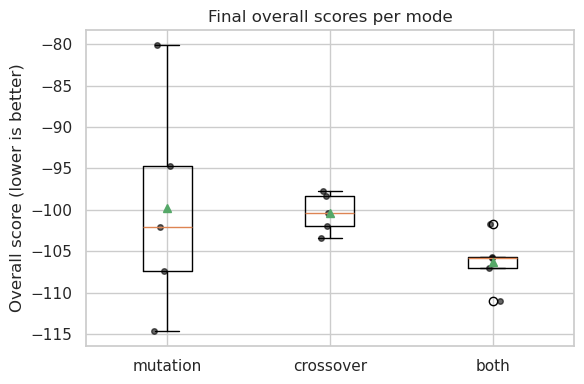

In [9]:
plt.figure(figsize=(6, 4))
box_data = [final_scores.loc[final_scores["mode"] == mode, "score"].values for mode in MODE_DIRS]
plt.boxplot(box_data, labels=list(MODE_DIRS.keys()), showmeans=True)
for idx, mode in enumerate(MODE_DIRS.keys(), start=1):
    y = final_scores.loc[final_scores["mode"] == mode, "score"].values
    x = np.random.normal(idx, 0.04, size=len(y))
    plt.plot(x, y, "o", alpha=0.6, color="black", markersize=4)
plt.title("Final overall scores per mode")
plt.ylabel("Overall score (lower is better)")
plt.xlabel("")
plt.tight_layout()
plt.show()



/tmp/ipykernel_834987/3793323511.py:3: FutureWarning: The provided callable <function mean at 0x75d5441dd280> is currently using DataFrameGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  pivot = df.pivot_table(index="iteration", values="score", aggfunc=[np.mean, np.std])
/tmp/ipykernel_834987/3793323511.py:3: FutureWarning: The provided callable <function std at 0x75d5441dd3a0> is currently using DataFrameGroupBy.std. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "std" instead.
  pivot = df.pivot_table(index="iteration", values="score", aggfunc=[np.mean, np.std])


ValueError: 'y1' is not 1-dimensional

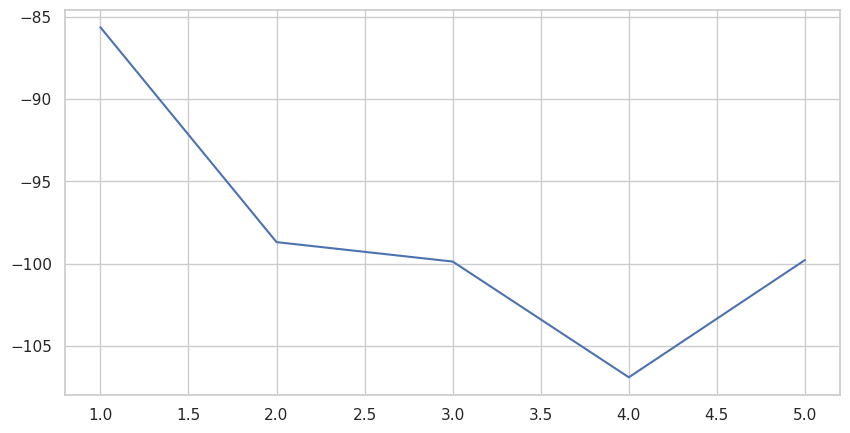

In [ ]:
fig, ax = plt.subplots(figsize=(10, 5))
for mode, df in mode_dfs.items():
    stats = df.groupby("iteration")['score'].agg(['mean', 'std']).reset_index()
    mean = stats['mean'].values
    std = stats['std'].fillna(0).values
    iters = stats['iteration'].values
    ax.plot(iters, mean, label=mode)
    ax.fill_between(iters, mean - std, mean + std, alpha=0.2)

ax.set_xlabel("Iteration")
ax.set_ylabel("Overall score (mean ± std)")
ax.set_title("Convergence of overall score by mode")
ax.grid(True, alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()



In [ ]:
all_scores.head(10)



## Observations

- The table above (`summary`) shows the average, median, spread and extrema of the final overall scores for each mode.
- The plots illustrate both the distribution of the final scores and the mean ± standard deviation convergence curves across iterations.
- Remember that the overall score is minimised; lower curves and boxplots correspond to better performance.

